# Data Annotation

In this notebook, we will create a annotation dataset based on different subsets of data, look at the quality of the dataset, and determine a good CodeBERT cutoff score

In [2]:
import pandas as pd
import numpy as np
import json
import matplotlib.pyplot as plt

In [3]:
data_folder = "/data/group_data/code_edits"

## Create the annotation dataset

In [3]:
def sample_large_prefix_suffix(df, n=5):
    # using 600 as a threshold since we observed 98% of snapshot files have <600 lines difference
    full_lines = df['outcome_full_file'].apply(lambda x: len(str(x).splitlines()))
    snippet_lines = df['outcome_snippet'].apply(lambda x: len(str(x).splitlines()))
    mask = (full_lines - snippet_lines) >= 600
    candidates = df[mask]
    sampled_ids = np.random.choice(candidates['outcome_pair_id'].unique(), size=min(n, mask.sum(), \
            len(candidates['outcome_pair_id'].unique())), replace=False)
    return df[df['outcome_pair_id'].isin(sampled_ids)]

def sample_long_trajectories(df, n=5):
    # using 70 as a threshold since we observed 98% of snapshot files have <70 lines difference
    traj_counts = df.groupby('outcome_pair_id').size()
    long_ids = traj_counts[traj_counts >= 70].index
    sampled_ids = np.random.choice(long_ids, size=min(n, len(long_ids)), replace=False)
    return df[df['outcome_pair_id'].isin(sampled_ids)]

def sample_starts_ends(df, n=5):
    temp_df = df.copy()
    temp_df['outcome_full_lines'] = df['outcome_full_file'].apply(lambda x: len(str(x).splitlines()))
    
    full_snippet_mask = (
        (temp_df['outcome_snippet_start_line'] == 1) &
        (temp_df['outcome_snippet_end_line'] == temp_df['outcome_full_lines'])
    )
    candidates = temp_df[full_snippet_mask]
    if candidates.empty:
        return pd.DataFrame(columns=df.columns)
    
    sampled_ids = np.random.choice(
        candidates['outcome_pair_id'].unique(),
        size=min(n, len(candidates['outcome_pair_id'].unique())), 
        replace=False
    )
    
    sampled_df = df[df['outcome_pair_id'].isin(sampled_ids)].copy()
    sampled_df.drop(columns='outcome_full_lines', inplace=True)
    return sampled_df

def sample_inline_outcomes(df, n=5):
    matches = df['outcome_snippet'].str.strip() == df['outcome'].str.strip()
    inline_ids = df[~matches]['outcome_pair_id'].unique()
    sampled_ids = np.random.choice(inline_ids, size=min(n, len(inline_ids)), replace=False)
    return df[df['outcome_pair_id'].isin(sampled_ids)]

def sample_full_line_outcomes(df, n=5):
    matches = df['outcome_snippet'].str.strip() == df['outcome'].str.strip()
    full_ids = df[matches]['outcome_pair_id'].unique()
    sampled_ids = np.random.choice(full_ids, size=min(n, len(full_ids)), replace=False)
    return df[df['outcome_pair_id'].isin(sampled_ids)]

def sample_random(df, n=20):
    sampled_ids = np.random.choice(df['outcome_pair_id'].unique(), size=n, replace=False)
    return df[df['outcome_pair_id'].isin(sampled_ids)]

def sample_super_long(df, n=5):
    # using 21 as a threshold since we observed 98% of snapshot files have <=21 lines difference
    snippet_lines = df['outcome_snippet'].apply(lambda x: len(str(x).splitlines()))
    long_ids = df[snippet_lines > 21]['outcome_pair_id'].unique()
    sampled_ids = np.random.choice(long_ids, size=min(n, len(long_ids)), replace=False)
    return df[df['outcome_pair_id'].isin(sampled_ids)]

def build_manual_edit_dataset(dataset_df):
    used_ids = set()
    subsets = []

    def first_and_last(df):
        df = df.sort_values("edit_timestamp")
        return pd.concat([df.iloc[:1], df.iloc[-1:]])

    def unique_sample(sampler, df, n, label):
        available_df = df[~df['outcome_pair_id'].isin(used_ids)]
        sampled = sampler(available_df, n)
        if not sampled.empty:
            sampled = sampled.copy()
            sampled["source"] = label
            used_ids.update(sampled['outcome_pair_id'].unique())
        return sampled

    subsets.append(unique_sample(sample_large_prefix_suffix, dataset_df, 5, "large_prefix_suffix"))
    subsets.append(unique_sample(sample_long_trajectories, dataset_df, 5, "long_trajectory"))
    subsets.append(unique_sample(sample_starts_ends, dataset_df, 5, "start_end"))
    subsets.append(unique_sample(sample_inline_outcomes, dataset_df, 5, "inline_outcome"))
    subsets.append(unique_sample(sample_full_line_outcomes, dataset_df, 5, "full_line_outcome"))
    subsets.append(unique_sample(sample_super_long, dataset_df, 5, "super_long"))
    subsets.append(unique_sample(sample_random, dataset_df, 20, "random"))
    
    combined = pd.concat([s for s in subsets if s is not None and not s.empty])
    combined = (combined.groupby("outcome_pair_id").apply(first_and_last).reset_index(drop=True))

    return combined

In [4]:
datasets = []
for i in range(137):
    df = pd.read_csv(f"{data_folder}/dataset_batch{i}.csv")
    datasets.append(df)
dataset_df = pd.concat(datasets, ignore_index=True)

outcomes = []
for i in range(137):
    df = pd.read_csv(f"{data_folder}/outcomes_batch{i}.csv")
    outcomes.append(df)
outcomes_df = pd.concat(outcomes, ignore_index=True)

# Merge keeping all rows of dataset_df, and only the fileType column from outcomes_df
dataset_df = dataset_df.merge(
    outcomes_df[['pairId', 'fileType']],
    left_on='outcome_pair_id',
    right_on='pairId',
    how='left'
)
dataset_df = dataset_df.drop(columns=['pairId'])
dataset_df = dataset_df[dataset_df["codebert_score"] > 0.68]

np.random.seed(42)
manual_dataset_python = build_manual_edit_dataset(dataset_df[dataset_df["fileType"] == "python"])
manual_dataset_js = build_manual_edit_dataset(dataset_df[dataset_df["fileType"] == "javascript"])
manual_dataset_ts = build_manual_edit_dataset(dataset_df[dataset_df["fileType"] == "typescript"])
manual_dataset = pd.concat([manual_dataset_python, manual_dataset_js, manual_dataset_ts], ignore_index=True)

print("Final sampled dataset shape:", manual_dataset.shape)
print("Number of unique trajectories:", manual_dataset['outcome_pair_id'].nunique())

manual_dataset.to_csv("manual_edit_dataset_unlabeled.csv", index=False)

/tmp/ipykernel_2497137/2038090919.py:89: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  combined = (combined.groupby("outcome_pair_id").apply(first_and_last).reset_index(drop=True))
/tmp/ipykernel_2497137/2038090919.py:89: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  combined = (combined.groupby("outcome_pair_id").apply(first_and_last).reset_index(drop=True))
/tmp/ipykernel_2497137/2038090919.py:89: Depreca

Final sampled dataset shape: (250, 24)
Number of unique trajectories: 125


## Data Exploration

In [4]:
user_ids = json.load(open(f"{data_folder}/user_ids.json", "r"))
num_batches = len(user_ids)
total_users = num_batches * 30  # each batch has 30 users
print(f"Total number of users: {total_users}")

Total number of users: 4110


In [5]:
datasets = []
for i in range(num_batches):
    df = pd.read_csv(f"{data_folder}/dataset_batch{i}.csv")
    datasets.append(df)
dataset_df = pd.concat(datasets, ignore_index=True)

print("Dataset length:", len(dataset_df))

Dataset length: 77980


In [6]:
outcomes = []
for i in range(num_batches):
    df = pd.read_csv(f"{data_folder}/outcomes_batch{i}.csv")
    outcomes.append(df)
outcomes_df = pd.concat(outcomes, ignore_index=True)

print(f"Total number of outcomes: {len(outcomes_df)}")

Total number of outcomes: 40149


In [7]:
num_trajectories = len(dataset_df["outcome_completion_id"].unique())

print("Number of trajectories:", num_trajectories)
print(f"So, {num_trajectories*100/len(outcomes_df)}% of outcomes have a trajectory associated with it (shortlisted by lang, models, etc)")

Number of trajectories: 6039
So, 15.041470522304415% of outcomes have a trajectory associated with it (shortlisted by lang, models, etc)


In [8]:
dataset_df = dataset_df.merge(
    outcomes_df[['pairId', 'fileType']],
    left_on='outcome_pair_id',
    right_on='pairId',
    how='left'
)
dataset_df = dataset_df.drop(columns=['pairId'])
print("Total number of edits by language:")
dataset_df['fileType'].value_counts().head()

Total number of edits by language:


fileType
python        57963
javascript    10981
typescript     9036
Name: count, dtype: int64

In [9]:
print("Total number of outcomes by language:")
outcomes_df['fileType'].value_counts().head()

Total number of outcomes by language:


fileType
python             17551
javascript          2989
typescript          2133
typescriptreact     2076
html                1573
Name: count, dtype: int64

In [10]:
dataset_df["outcome_full_snippet"] = dataset_df["outcome_full_snippet"].fillna("")
dataset_df["edit_full_snippet"] = dataset_df["edit_full_snippet"].fillna("")
dataset_df["edit_snippet"] = dataset_df["edit_snippet"].fillna("")
dataset_df["time_since_completion"] = dataset_df["edit_timestamp"] - dataset_df["outcome_timestamp"]
dataset_df['edit_timestamp_readable'] = pd.to_datetime(dataset_df['edit_timestamp'], unit='s')

## Subset Analysis

### Size of prefix/suffix

/tmp/ipykernel_2881572/3526737787.py:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["bin", "language"])


Threshold for top 98% longest prefix+suffix (javascript): 809.0
Threshold for top 98% longest prefix+suffix (typescript): 343.0
Threshold for top 98% longest prefix+suffix (python): 608.0
83.0 44.0 129.0


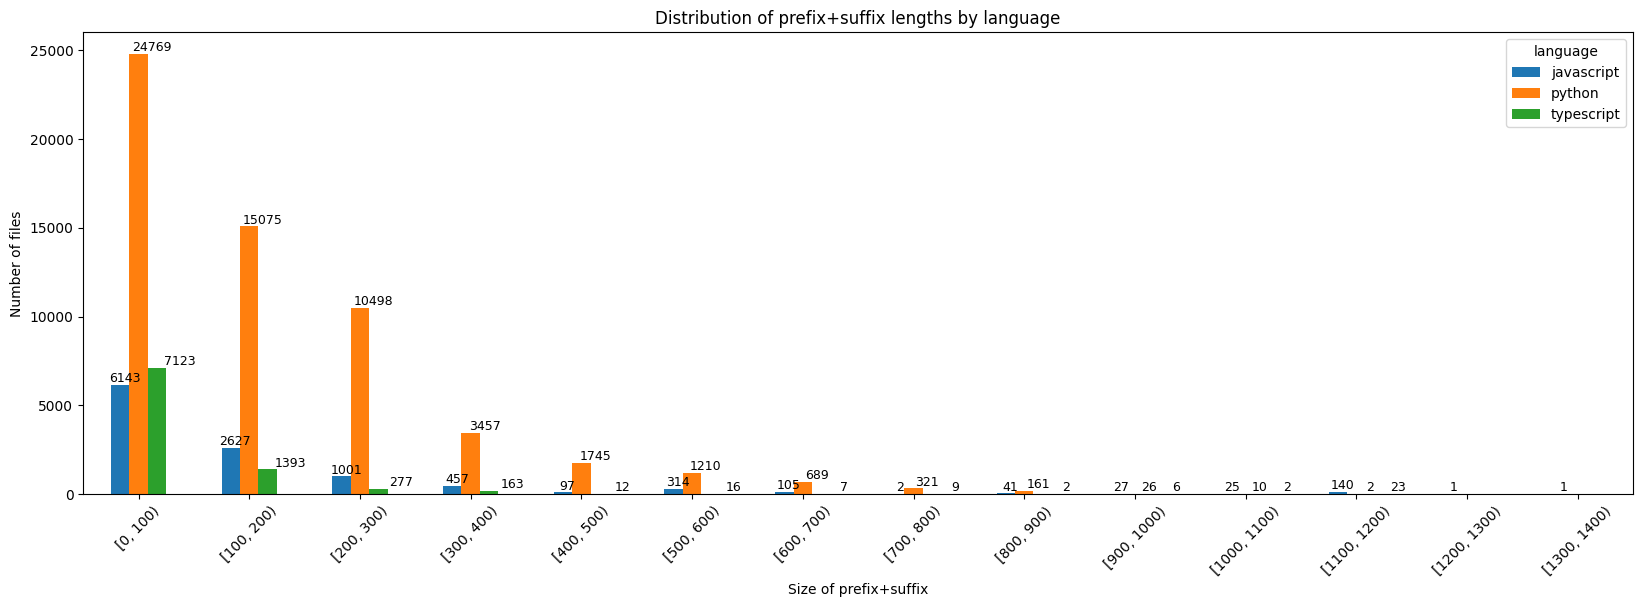

: 

In [ ]:
full_lines = dataset_df['outcome_full_file'].apply(lambda x: len(str(x).splitlines()))
snippet_lines = dataset_df['outcome_snippet'].apply(lambda x: len(str(x).splitlines()))
line_diffs = full_lines - snippet_lines

max_diff = line_diffs.max()
min_diff = line_diffs.min()
bins = np.arange(min_diff - (min_diff % 10), max_diff + 10, 100)
binned = pd.cut(line_diffs, bins=bins, right=False)
bin_counts = (
    pd.DataFrame({"bin": binned, "language": dataset_df["fileType"]})
    .groupby(["bin", "language"])
    .size()
    .unstack(fill_value=0)
)
bin_counts = bin_counts[(bin_counts.sum(axis=1) > 0)]

ax = bin_counts.plot(kind='bar', figsize=(20,6))
plt.xlabel('Size of prefix+suffix')
plt.ylabel('Number of files')
plt.title('Distribution of prefix+suffix lengths by language')
plt.xticks(rotation=45)

for i, (idx, row) in enumerate(bin_counts.iterrows()):
    for j, lang in enumerate(row.index):
        v = row[lang]
        if v > 0:
            ax.text(i + (j - 0.5) * 0.25, v + 0.5, str(v),
                    ha="center", va="bottom", fontsize=9)

js_threshold = np.percentile(line_diffs[dataset_df["fileType"] == "javascript"], 98)
ts_threshold = np.percentile(line_diffs[dataset_df["fileType"] == "typescript"], 98)
py_threshold = np.percentile(line_diffs[dataset_df["fileType"] == "python"], 98)

print(f"Threshold for top 98% longest prefix+suffix (javascript): {js_threshold}")
print(f"Threshold for top 98% longest prefix+suffix (typescript): {ts_threshold}")
print(f"Threshold for top 98% longest prefix+suffix (python): {py_threshold}")

js_median = np.median(line_diffs[dataset_df["fileType"] == "javascript"])
ts_median = np.median(line_diffs[dataset_df["fileType"] == "typescript"])
py_median = np.median(line_diffs[dataset_df["fileType"] == "python"])

print(js_median, ts_median, py_median)
plt.show()

### Length of trajectory

/tmp/ipykernel_2497648/3577419378.py:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  bin_counts = trajectory_counts.groupby(['bin', 'fileType']).size().unstack(fill_value=0)


Threshold for top 98% longest trajectories (javascript): 67.07999999999993
Threshold for top 98% longest trajectories (typescript): 136.0
Threshold for top 98% longest trajectories (python): 76.0


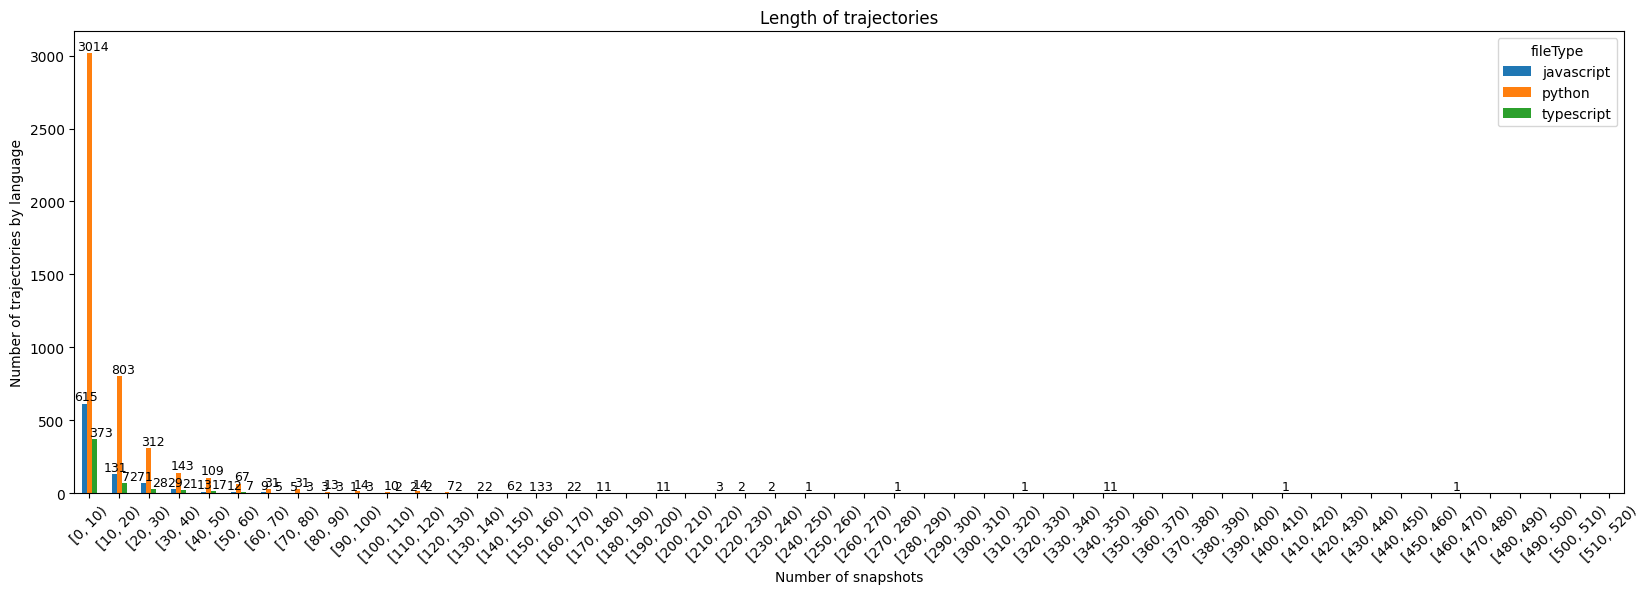

In [ ]:
trajectory_counts = dataset_df.groupby('outcome_completion_id').size().reset_index(name='count')
trajectory_counts = trajectory_counts.merge(
    dataset_df[['outcome_completion_id', 'fileType']].drop_duplicates('outcome_completion_id'),
    on='outcome_completion_id',
    how='left'
)

max_count = trajectory_counts['count'].max()
bins = np.arange(0, max_count + 10, 10)  # step=10
trajectory_counts['bin'] = pd.cut(trajectory_counts['count'], bins=bins, right=False)
bin_counts = trajectory_counts.groupby(['bin', 'fileType']).size().unstack(fill_value=0)

ax = bin_counts.plot(kind='bar', figsize=(20,6))
plt.xlabel('Number of snapshots')
plt.ylabel('Number of trajectories by language')
plt.title('Length of trajectories')
plt.xticks(rotation=45)

for i, (idx, row) in enumerate(bin_counts.iterrows()):
    for j, lang in enumerate(row.index):
        v = row[lang]
        if v > 0:
            ax.text(i + (j - 0.5) * 0.25, v + 0.5, str(v),
                    ha="center", va="bottom", fontsize=9)

js_threshold = np.percentile(
    trajectory_counts.loc[trajectory_counts['fileType'] == 'javascript', 'count'], 98
)
ts_threshold = np.percentile(
    trajectory_counts.loc[trajectory_counts['fileType'] == 'typescript', 'count'], 98
)
py_threshold = np.percentile(
    trajectory_counts.loc[trajectory_counts['fileType'] == 'python', 'count'], 98
)

print(f"Threshold for top 98% longest trajectories (javascript): {js_threshold}")
print(f"Threshold for top 98% longest trajectories (typescript): {ts_threshold}")
print(f"Threshold for top 98% longest trajectories (python): {py_threshold}")
plt.show()

### Length of outcome

/tmp/ipykernel_2875968/1675998823.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  remaining["bin"] = pd.cut(remaining["lines"], bins=bins, right=False)
/tmp/ipykernel_2875968/1675998823.py:13: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  bin_counts = remaining.groupby(["bin", "language"]).size().unstack(fill_value=0)


Threshold for top 98% longest snippets (javascript): 21.0
Threshold for top 98% longest snippets (typescript): 21.0
Threshold for top 98% longest snippets (python): 21.0


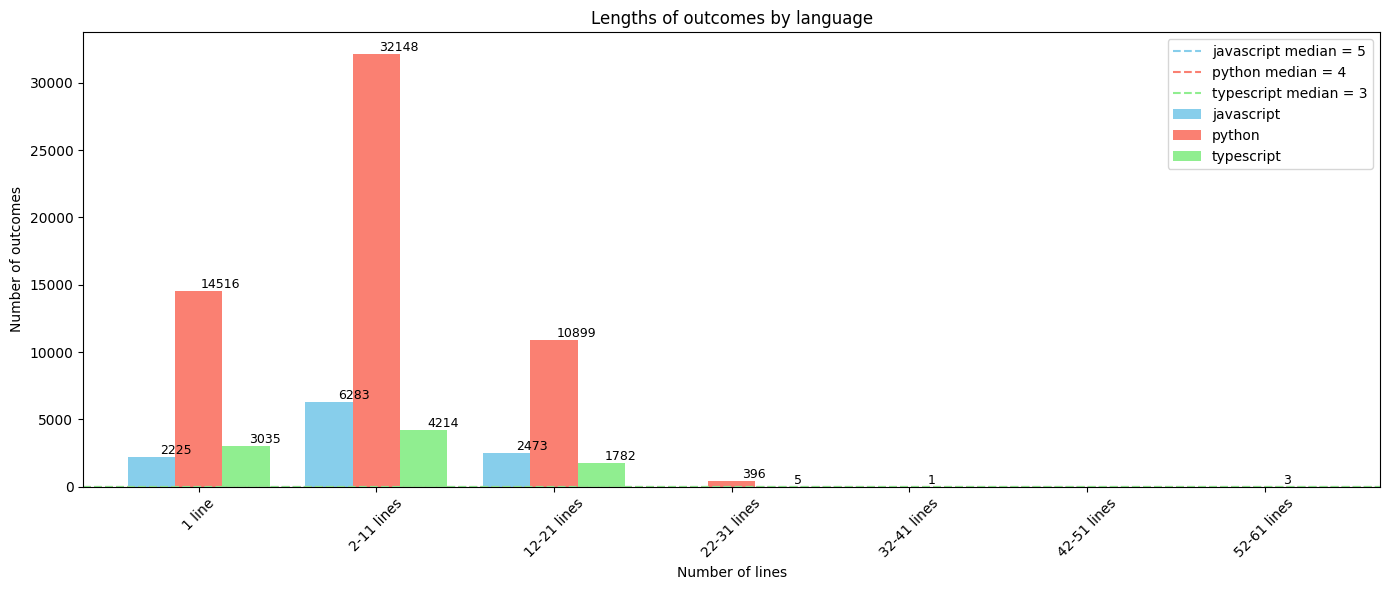

: 

In [ ]:
snippet_lines = dataset_df['outcome_snippet'].apply(lambda x: len(str(x).splitlines()))
is_one_line = snippet_lines == 1
snip_df = pd.DataFrame({
    "lines": snippet_lines,
    "language": dataset_df["fileType"]
})
one_line_counts = snip_df[is_one_line].groupby("language").size()
remaining = snip_df[~is_one_line]


max_lines = remaining["lines"].max()
bins = np.arange(2, max_lines + 10, 10)
remaining["bin"] = pd.cut(remaining["lines"], bins=bins, right=False)
bin_counts = remaining.groupby(["bin", "language"]).size().unstack(fill_value=0)
one_line_row = pd.DataFrame([one_line_counts], index=["1 line"]).fillna(0).astype(int)
bin_counts.index = bin_counts.index.map(lambda x: f"{x.left}-{x.right-1} lines")
bin_counts = pd.concat([one_line_row, bin_counts])


fig, ax = plt.subplots(figsize=(14,6))
bin_counts.plot(kind="bar", stacked=False, ax=ax, width=0.8)
plt.xlabel("Number of lines")
plt.ylabel("Number of outcomes")
plt.title("Lengths of outcomes by language")
plt.xticks(rotation=45)

for i, (idx, row) in enumerate(bin_counts.iterrows()):
    for j, lang in enumerate(row.index):
        v = row[lang]
        if v > 0:
            ax.text(i + (j - 0.5) * 0.25, v + 0.5, str(v),
                    ha="center", va="bottom", fontsize=9)

js_threshold = np.percentile(snip_df.loc[snip_df['language']=="javascript", "lines"], 98)
ts_threshold = np.percentile(snip_df.loc[snip_df['language']=="typescript", "lines"], 98)
py_threshold = np.percentile(snip_df.loc[snip_df['language']=="python", "lines"], 98)

print(f"Threshold for top 98% longest snippets (javascript): {js_threshold}")
print(f"Threshold for top 98% longest snippets (typescript): {ts_threshold}")
print(f"Threshold for top 98% longest snippets (python): {py_threshold}")

plt.show()

### Position of outcome

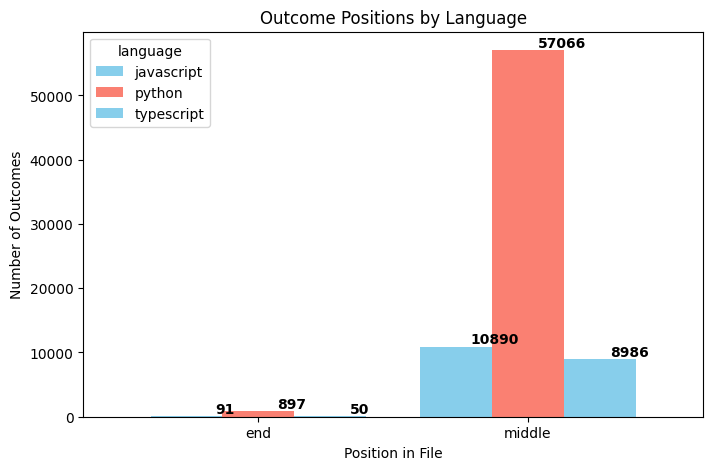

In [14]:
line_counts = dataset_df['outcome_full_file'].apply(lambda x: len(str(x).splitlines()))
conditions = [
    dataset_df['outcome_snippet_start_line'] == 1,
    dataset_df['outcome_snippet_end_line'] == line_counts
]
choices = ['start', 'end']
positions = np.select(conditions, choices, default='middle')

pos_df = pd.DataFrame({
    "position": positions,
    "language": dataset_df["fileType"]
})
counts = pos_df.groupby(["position", "language"]).size().unstack(fill_value=0)

fig, ax = plt.subplots(figsize=(8,5))
counts.plot(kind="bar", stacked=False, ax=ax, color=['skyblue','salmon'], width=0.8)
plt.title("Outcome Positions by Language")
plt.ylabel("Number of Outcomes")
plt.xlabel("Position in File")
plt.xticks(rotation=0)

for i, (idx, row) in enumerate(counts.iterrows()):
    for j, lang in enumerate(row.index):
        v = row[lang]
        if v > 0:
            ax.text(i + (j - 0.5) * 0.25, v + 0.5, str(v),
                    ha="center", va="bottom", fontsize=10, fontweight='bold')

plt.show()

### Starting line position of outcome

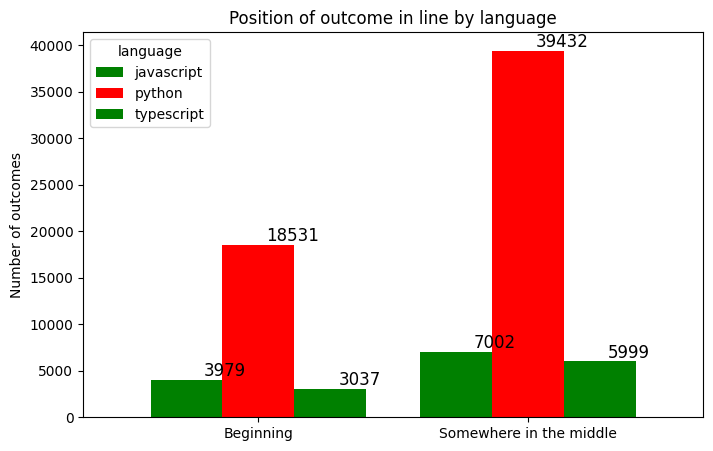

In [15]:
matches = dataset_df['outcome_snippet'].str.strip() == dataset_df['outcome'].str.strip()
positions = matches.map({True: 'Beginning', False: 'Somewhere in the middle'})
match_df = pd.DataFrame({
    "position": positions,
    "language": dataset_df["fileType"]
})
counts = match_df.groupby(["position", "language"]).size().unstack(fill_value=0)

fig, ax = plt.subplots(figsize=(8,5))
counts.plot(kind="bar", stacked=False, ax=ax, color=['green', 'red'], width=0.8)
plt.xlabel('')
plt.ylabel('Number of outcomes')
plt.title('Position of outcome in line by language')
plt.xticks(rotation=0)

for i, (idx, row) in enumerate(counts.iterrows()):
    for j, lang in enumerate(row.index):
        v = row[lang]
        if v > 0:
            ax.text(i + (j - 0.5) * 0.25, v + 0.5, str(v),
                    ha="center", va="bottom", fontsize=12)

plt.show()

## Annotations Analysis

Here, we look over the ~200 edits that we annotated (100 per language). From this, we gather that our dataset is of good quality, as the character overlap between the correct edit and extracted edit is 87.4%. We created this annotation dataset by looking at the first and last edit in a trajectory for 100 randomly sampled trajectories.  

In [16]:
annotated_df = pd.read_csv(f'{data_folder}/manual_edit_dataset_final.csv')
annotated_df['edit correct?'] = annotated_df['edit correct?'].str.lower()
annotated_df['full edit snippet correct?'] = annotated_df['full edit snippet correct?'].str.lower()
annotated_df['edit_snippet'] = annotated_df['edit_snippet'].fillna('').astype(str)
annotated_df['actual_edit'] = annotated_df['actual_edit'].fillna('').astype(str)
annotated_df['edit_full_snippet'] = annotated_df['edit_full_snippet'].fillna('').astype(str)
annotated_df['actual_full_edit'] = annotated_df['actual_full_edit'].fillna('').astype(str)
annotated_df.loc[annotated_df['edit correct?'] == 'yes', 'actual_edit'] = annotated_df.loc[annotated_df['edit correct?'] == 'yes', 'edit_snippet']
annotated_df.loc[annotated_df['full edit snippet correct?'] == 'yes', 'actual_full_edit'] = \
    annotated_df.loc[annotated_df['full edit snippet correct?'] == 'yes', 'edit_full_snippet']

### Edit Snippet

In [17]:
from collections import Counter
def compute_overlaps(row):
    edit_text = str(row['edit_snippet']) if pd.notna(row['edit_snippet']) else ''
    actual_text = str(row['actual_edit']) if pd.notna(row['actual_edit']) else ''
    edit_lines = [l.strip() for l in edit_text.splitlines()]
    actual_lines = [l.strip() for l in actual_text.splitlines()]

    edit_counter = Counter(edit_lines)
    actual_counter = Counter(actual_lines)

    overlap = sum((edit_counter & actual_counter).values())
    total = sum(actual_counter.values())

    # Important: if both are empty, define overlap as 1.0 (perfect match)
    if len(edit_lines) == 0 and len(actual_lines) == 0:
        line_overlap_pct = 1.0
    else:
        line_overlap_pct = overlap / total if total > 0 else 0.0

    # --- Character-level overlap ---
    edit_chars = list(edit_text.replace("\n", ""))
    actual_chars = list(actual_text.replace("\n", ""))

    char_counter_edit = Counter(edit_chars)
    char_counter_actual = Counter(actual_chars)

    char_overlap = sum((char_counter_edit & char_counter_actual).values())
    char_total = sum(char_counter_actual.values())

    if len(edit_chars) == 0 and len(actual_chars) == 0:
        char_overlap_pct = 1.0
    else:
        char_overlap_pct = char_overlap / char_total if char_total > 0 else 0.0

    return pd.Series({
        "edit_line_overlap_pct": line_overlap_pct,
        "edit_char_overlap_pct": char_overlap_pct
    })

annotated_df = annotated_df.join(annotated_df.apply(compute_overlaps, axis=1))

In [18]:
# Counts + percentages
counts_overall = (
    annotated_df['edit correct?']
    .value_counts(dropna=False)
    .reset_index(name="count")
    .rename(columns={"index": "edit correct?"})
)
counts_overall["percentage"] = (
    counts_overall["count"] / counts_overall["count"].sum() * 100
)

# Mean line overlap by "edit correct?"
mean_by_correct = (
    annotated_df.groupby("edit correct?")[["edit_line_overlap_pct", "edit_char_overlap_pct"]]
    .mean()
    .mul(100)  # to %
    .reset_index()
)

# Count how many have missing/empty 'actual_edit'
empty_actual_edits = (
    annotated_df['actual_edit']
    .apply(lambda x: pd.isna(x) or str(x).strip() == "")
    .groupby(annotated_df['edit correct?'])
    .sum()
    .reset_index(name='empty_actual_edit_count')
)

# Merge all tables
summary_table = (
    counts_overall
    .merge(mean_by_correct, on="edit correct?", how="left")
    .merge(empty_actual_edits, on="edit correct?", how="left")
)

# Rename for clarity
summary_table = summary_table.rename(columns={
    "edit_line_overlap_pct": "mean_line_overlap_pct",
    "edit_char_overlap_pct": "mean_char_overlap_pct"
})

# Add overall averages
average_line_overlap = annotated_df['edit_line_overlap_pct'].mean()
average_char_overlap = annotated_df['edit_char_overlap_pct'].mean()
print(f"Average line overlap across all rows: {average_line_overlap:.3f}")
print(f"Average char overlap across all rows: {average_char_overlap:.3f}")

summary_table

Average line overlap across all rows: 0.867
Average char overlap across all rows: 0.881


,edit correct?,count,percentage,mean_line_overlap_pct,mean_char_overlap_pct,empty_actual_edit_count
0,yes,186,66.192171,100.000000,100.000000,41
1,includes extra,63,22.419929,84.509565,84.909404,10
2,incomplete,17,6.049822,21.087344,26.208057,0
3,no,15,5.338078,4.957265,23.894546,11


In [19]:
annotated_df.groupby("source")["edit correct?"] \
    .value_counts(dropna=False) \
    .reset_index(name="count") \
    .assign(percentage=lambda d: d["count"] / d.groupby("source")["count"].transform("sum") * 100)

,source,edit correct?,count,percentage
0,full_line_outcome,yes,13,44.827586
1,full_line_outcome,includes extra,12,41.379310
2,full_line_outcome,incomplete,4,13.793103
3,inline_outcome,yes,12,54.545455
4,inline_outcome,includes extra,5,22.727273
5,inline_outcome,no,3,13.636364
6,inline_outcome,incomplete,2,9.090909
7,large_prefix_suffix,yes,12,54.545455
8,large_prefix_suffix,includes extra,6,27.272727
9,large_prefix_suffix,incomplete,2,9.090909


In [20]:
mean_by_correct = (
    annotated_df.groupby("source")[["edit_line_overlap_pct", "edit_char_overlap_pct"]]
    .mean()
    .mul(100)  # to %
    .reset_index()
)
mean_by_correct

,source,edit_line_overlap_pct,edit_char_overlap_pct
0,full_line_outcome,81.149425,82.251521
1,inline_outcome,80.303030,81.453218
2,large_prefix_suffix,81.818182,81.818182
3,long_trajectory,83.897436,85.749476
4,random,91.509434,92.692901
5,super_long,76.612277,88.230509
6,zero_codebert,73.333333,73.333333


### Full edit snippet

In [21]:
from collections import Counter
def compute_overlaps(row):
    edit_text = str(row['edit_full_snippet']) if pd.notna(row['edit_full_snippet']) else ''
    actual_text = str(row['actual_full_edit']) if pd.notna(row['actual_full_edit']) else ''

    edit_lines = [l.strip() for l in edit_text.splitlines()]
    actual_lines = [l.strip() for l in actual_text.splitlines()]

    edit_counter = Counter(edit_lines)
    actual_counter = Counter(actual_lines)

    overlap = sum((edit_counter & actual_counter).values())
    total = sum(actual_counter.values())

    if len(edit_lines) == 0 and len(actual_lines) == 0:
        line_overlap_pct = 1.0
    else:
        line_overlap_pct = overlap / total if total > 0 else 0.0

    edit_chars = list(edit_text.replace("\n", ""))
    actual_chars = list(actual_text.replace("\n", ""))

    char_counter_edit = Counter(edit_chars)
    char_counter_actual = Counter(actual_chars)

    char_overlap = sum((char_counter_edit & char_counter_actual).values())
    char_total = sum(char_counter_actual.values())

    if len(edit_chars) == 0 and len(actual_chars) == 0:
        char_overlap_pct = 1.0
    else:
        char_overlap_pct = char_overlap / char_total if char_total > 0 else 0.0

    return pd.Series({
        "full_edit_line_overlap_pct": line_overlap_pct,
        "full_edit_char_overlap_pct": char_overlap_pct
    })

annotated_df = annotated_df.join(annotated_df.apply(compute_overlaps, axis=1))

In [22]:
# Counts + percentages
counts_overall = (
    annotated_df['full edit snippet correct?']
    .value_counts(dropna=False)
    .reset_index(name="count")
    .rename(columns={"index": "full edit snippet correct?"})
)
counts_overall["percentage"] = (
    counts_overall["count"] / counts_overall["count"].sum() * 100
)

# Mean line overlap by "edit correct?"
mean_by_correct = (
    annotated_df.groupby("full edit snippet correct?")[["full_edit_line_overlap_pct", "full_edit_char_overlap_pct"]]
    .mean()
    .mul(100)  # to %
    .reset_index()
)

# Merge into one table
summary_table = counts_overall.merge(mean_by_correct, on="full edit snippet correct?", how="left")
summary_table = summary_table.rename(columns={
    "full_edit_line_overlap_pct": "mean_line_overlap_pct",
    "full_edit_char_overlap_pct": "mean_char_overlap_pct"
})

average_line_overlap = annotated_df['full_edit_line_overlap_pct'].mean()
average_char_overlap = annotated_df['full_edit_char_overlap_pct'].mean()
print(f"Average line overlap across all rows: {average_line_overlap:.3f}")
print(f"Average char overlap across all rows: {average_char_overlap:.3f}")

summary_table

Average line overlap across all rows: 0.877
Average char overlap across all rows: 0.890


,full edit snippet correct?,count,percentage,mean_line_overlap_pct,mean_char_overlap_pct
0,yes,175,62.277580,100.000000,100.000000
1,includes extra,76,27.046263,88.309410,89.419589
2,incomplete,16,5.693950,23.883929,27.111348
3,no,14,4.982206,3.401361,18.987743


In [23]:
annotated_df.groupby("source")["full edit snippet correct?"] \
    .value_counts(dropna=False) \
    .reset_index(name="count") \
    .assign(percentage=lambda d: d["count"] / d.groupby("source")["count"].transform("sum") * 100)

,source,full edit snippet correct?,count,percentage
0,full_line_outcome,includes extra,13,44.827586
1,full_line_outcome,yes,13,44.827586
2,full_line_outcome,incomplete,3,10.344828
3,inline_outcome,yes,13,59.090909
4,inline_outcome,includes extra,5,22.727273
5,inline_outcome,no,3,13.636364
6,inline_outcome,incomplete,1,4.545455
7,large_prefix_suffix,yes,13,59.090909
8,large_prefix_suffix,includes extra,6,27.272727
9,large_prefix_suffix,no,2,9.090909


In [24]:
mean_by_correct = (
    annotated_df.groupby("source")[["full_edit_line_overlap_pct", "full_edit_char_overlap_pct"]]
    .mean()
    .mul(100)  # to %
    .reset_index()
)
mean_by_correct

,source,full_edit_line_overlap_pct,full_edit_char_overlap_pct
0,full_line_outcome,79.080460,79.310345
1,inline_outcome,81.818182,81.818182
2,large_prefix_suffix,86.363636,86.363636
3,long_trajectory,88.000000,88.000000
4,random,92.890836,94.275021
5,super_long,64.255652,78.418939
6,zero_codebert,73.333333,73.333333


## Filtering by CodeBERT

Based on annotation work and some basic data analysis, we can filter out data based on the CodeBERT score. 

With a cutoff of 0.6830752491950989, we would keep 52780 edits out of 77980 edits


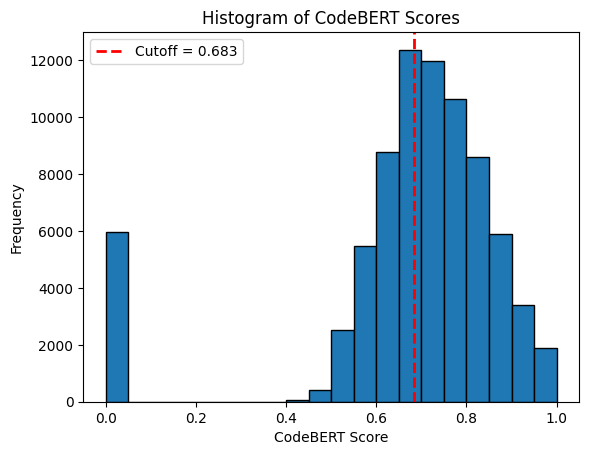

: 

In [ ]:
similarity_scores = dataset_df["codebert_score"]
similarity_scores = pd.to_numeric(similarity_scores, errors='coerce')
similarity_scores = similarity_scores.dropna()

nonzero_similarity_scores = similarity_scores[similarity_scores > 0]
cutoff = nonzero_similarity_scores.quantile(0.35)

filtered_similarity_scores = similarity_scores[(similarity_scores >= cutoff) | (similarity_scores == 0.0)]
print(f"With a cutoff of {cutoff}, we would keep {len(filtered_similarity_scores)} edits out of {len(similarity_scores)} edits")

plt.hist(similarity_scores, bins=20, edgecolor='black')
plt.axvline(cutoff, color='red', linestyle='dashed', linewidth=2, label=f'Cutoff = {cutoff:.3f}')
plt.xlabel('CodeBERT Score')
plt.ylabel('Frequency')
plt.title('Histogram of CodeBERT Scores')
plt.legend()
plt.show()